The goal of this file is evaluate relevancy of the returned answers.

In [31]:
import os
import logging
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
# to reduce long log output
logging.getLogger("httpx").setLevel(logging.WARNING)
logging.getLogger("sentence_transformers").setLevel(logging.WARNING)
logging.getLogger("huggingface_hub").setLevel(logging.WARNING)

from langchain_ollama import ChatOllama
from rag_flow import RAGFlow
import matplotlib.pyplot as plt
from deepeval.metrics import AnswerRelevancyMetric
from deepeval.test_case import LLMTestCase
from deepeval.models import OllamaModel
import logging
import pandas as pd
from time import perf_counter
import os
import ast
import json


logging.getLogger("httpx").setLevel(logging.WARNING)


In [2]:
test_data = pd.read_csv("../component_level_eval/test_data/arxiv_classifier_300_questions.csv")
questions = test_data[test_data["label"] == "arxiv"]["question"]
questions.head(2)

0    What are the main limitations of economic grow...
2    What are the main limitations of operating sys...
Name: question, dtype: str

In [3]:
llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
)
classifier = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=15,
    reasoning=False,
    num_ctx=3000,
)

In [4]:
ans_models = {"llama": llama}

In [32]:
total_start = perf_counter()

for model_name, model in ans_models.items():
    params = {
        "query_model": llama,
        "answer_model": model,
        "titles_limit": 5,
        "top_k_titles": 5,
        "chunk_size": 200,
        "chunk_overlap_fraction": 0.2,
        "candidate_k": 20,
        "top_k_chunks": 10,
        "classifier": classifier
    }

    rag = RAGFlow(params)
    test_start = perf_counter()

    latencies = []
    answers = []

    for question in questions:
        start = perf_counter()

        answer = rag.run(question)["answer"]
        latency = perf_counter() - start
        latencies.append(latency)
        answers.append(answer)

    answers[f"{model_name}_latency"] = latencies
    answers[f"{model_name}_answers"] = answers

    test_length = perf_counter() - test_start
    print(f"{model_name}: {test_length / 60:.2f} min")

print(f"Total: {(perf_counter() - total_start) / 60:.2f} min")

answers.to_csv("rag_answers.csv", index=False)

In [5]:
answers = pd.read_csv("rag_answers.csv")
answers.head(2)

,question,llama_latency,llama_answers
0,What are the main limitations of economic grow...,19.43911,{'answer': 'Based on the provided arXiv contex...
1,What are the main limitations of operating sys...,18.68124,{'answer': 'Based on the provided context from...


In [6]:
print(f"Mean latency with Llama: {answers["llama_latency"].mean()} ")
print(f"The longest questions took {answers["llama_latency"].max()} seconds")
print(f"The quickest questions took {answers["llama_latency"].min()} seconds")

Mean latency with Llama: 15.6131993836537 
The longest questions took 35.97166966693476 seconds
The quickest questions took 0.8726844589691609 seconds


In [7]:
results = []

In [11]:
os.environ["DEEPEVAL_DISABLE_PROGRESS_BAR"] = "1"
batch_size = 15
start_index = 0
end_index = min(100, len(answers))
results_file = "relevancy_results.csv"


def extract_answer(value):
    if isinstance(value, str):
        try:
            value = json.loads(value)
        except (ValueError, TypeError):
            try:
                value = ast.literal_eval(value)
            except (ValueError, SyntaxError):
                return value

    if isinstance(value, dict):
        value = value.get("answer", value.get("text", ""))

        if isinstance(value, dict):
            value = value.get("text", "")

    if not isinstance(value, str):
        raise ValueError("Answer is not a string")

    return value


# Initialize judge model
gpt_judge = OllamaModel(
    model="gpt-oss:20b",
    base_url="http://localhost:11434"
)

metric = AnswerRelevancyMetric(
    model=gpt_judge,
    threshold=0.7,
    include_reason=True,
    async_mode=False,
    verbose_mode=False
)

try:
    results = pd.read_csv(results_file).to_dict("records")
except (FileNotFoundError, pd.errors.EmptyDataError):
    results = []

completed = {
    int(r["index"])
    for r in results
    if pd.notna(r.get("index"))
    and pd.notna(r.get("relevancy"))
}


# Run evaluation in batches
for start in range(start_index, end_index, batch_size):
    end = min(start + batch_size, end_index)

    for i in range(start, end):

        if i in completed:
            continue

        try:
            question = answers["question"].iloc[i]
            raw_output = answers["llama_answers"].iloc[i]

            output = extract_answer(raw_output)
            test_case = LLMTestCase(
                input=question,
                actual_output=output
            )

            metric.measure(test_case)

            if metric.score is not None:
                results.append({
                    "index": i,
                    "question": question,
                    "answer": output,
                    "relevancy": metric.score
                })

                completed.add(i)

        except Exception as e:
            print(
                f"ERROR at index {i}: "
                f"{type(e).__name__}: {e}"
            )

    results_df = pd.DataFrame(
        results,
        columns=["index", "question", "answer", "relevancy"]
    )

    results_df = (
        results_df
        .drop_duplicates(subset="index", keep="last")
        .sort_values("index")
    )

    results_df.to_csv(results_file, index=False)

    print(f"Completed batch: {start}–{end - 1}")



print("Evaluation finished!")
final_results = pd.read_csv(results_file)
print(f"Total evaluated questions: {final_results['relevancy'].notna().sum()}")
print(f"Mean relevancy: {final_results['relevancy'].mean():.3f}")
missing = (
    set(range(start_index, end_index))
    - set(final_results.loc[
        final_results["relevancy"].notna(), "index"
    ].astype(int))
)
print(f"Missing evaluations in first 83 questions: {sorted(missing)}")

In [10]:
# DeepEval timed out and threw an error, I could increase the wait time and start again, butI have collected enough results. 98 out of 150. I am not gonna start the cell again to save the
len(results)

98

In [13]:
relevancy_results = pd.read_csv("relevancy_results.csv")
relevancy_results.head(3)

,index,question,answer,relevancy
0,0,What are the main limitations of economic grow...,"Based on the provided arXiv context, I couldn'...",1.000000
1,1,What are the main limitations of operating sys...,"Based on the provided context from arXiv, the ...",0.923077
2,2,How can researchers evaluate optical interfere...,I couldn't find relevant scientific articles o...,0.000000


In [17]:
print(f"Mean relevancy is {relevancy_results["relevancy"].mean()} ")
print(f"null scores: {relevancy_results["relevancy"].isna().sum()}")

Mean relevancy is 0.7084155437621823 
null scores: 0


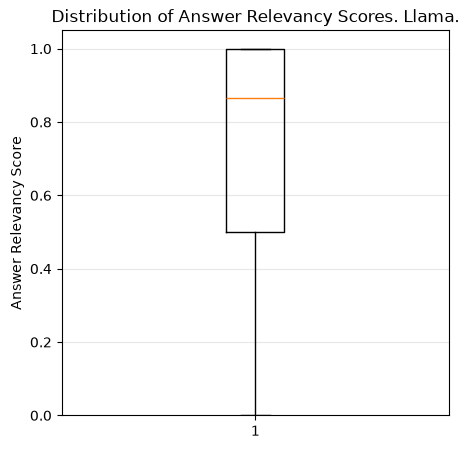

In [29]:
plt.figure(figsize=(5, 5))
plt.boxplot(relevancy_results["relevancy"])
plt.ylabel("Answer Relevancy Score")
plt.title("Distribution of Answer Relevancy Scores. Llama.")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.show()

As shown in the boxplot above, the median relevance score assigned by the GPT-based judge model is approximately 0.7. Additionally, 75% of the generated answers received relevance scoanswers of 0.35 or higher. I consider these answersults acceptable for the current stage of the system's development.

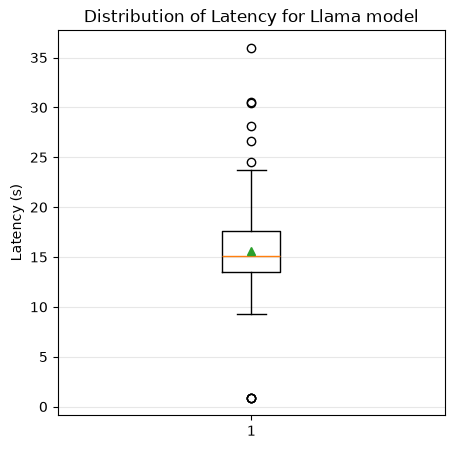

In [28]:
plt.figure(figsize=(5, 5))

plt.boxplot(
    answers["llama_latency"],
    showmeans=True
)

plt.ylabel("Latency (s)")
plt.title("Distribution of Latency for Llama model")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [30]:
latency = answers["llama_latency"].dropna()

print(f"Mean: {latency.mean():.2f} s")
print(f"Median: {latency.median():.2f} s")
print(f"P95: {latency.quantile(0.95):.2f} s")

Mean: 15.61 s
Median: 15.05 s
P95: 22.32 s


The mean and median are relatively close, indicating that the typical answersponse time is around 12–13 seconds. The P95 latency indicates that 95% of queries are processed within 22 seconds, while approximately 5% take longer. The difference between P95 and P50 (10.11 seconds) suggests that some queries require significantly more processing time.

Earler, I have generated answers using Qwen model and saved the answersults to the file. I was  measuring the latency for the entire flow. Below is the analisys of Qwen answer generation.

In [26]:
qwen_results= pd.read_csv("full_flow_default_res.csv")
qwen_results.head(3)

,questions,answer,latency
0,What are the main limitations of economic grow...,{'answer': 'The main limitations of economic g...,32.696086
1,What are the main limitations of operating sys...,{'answer': 'The main limitations of operating ...,44.832951
2,How can researchers evaluate optical interfere...,"{'answer': ""Researchers can evaluate optical i...",38.566016


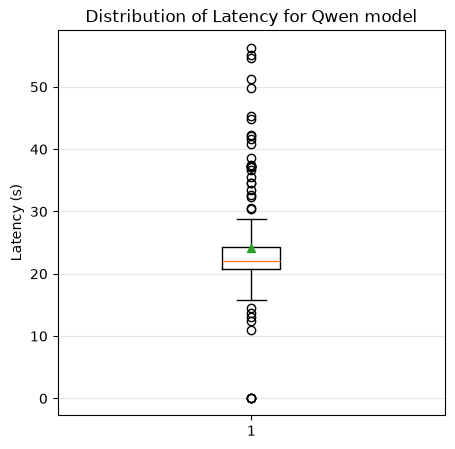

In [27]:
plt.figure(figsize=(5, 5))

plt.boxplot(
    qwen_results["latency"].dropna(),
    showmeans=True
)

plt.ylabel("Latency (s)")
plt.title("Distribution of Latency for Qwen model")
plt.grid(axis="y", alpha=0.3)

plt.show()


We can see that Qwen has taken more time on avarage to return an answer. I am not going to run the evaluation for the Qwen answer relevance, since it might take a long time.